In [1]:
import sys
sys.path.extend(['/mnt/dfc_data2/project/linyusen/project/85_rnalamp_package/'])
import spatialdata_plot  # noqa: F401
import spatialdata as sd
import matplotlib.pyplot as plt
import warnings
from rnalamp import rnalamp
from rnalamp import single_cell_query
from spatialdata import bounding_box_query

zarr_path = "/mnt/dfc_data3/project/linyusen/database/07_spatialdata/output-XETG00546__0076988__TMA__20251120__071742/annonate3/zhenfeng.AFL.spRNAseq.P1-NC.zarr"
sdata = sd.read_zarr(zarr_path)
sdata

SpatialData object, with associated Zarr store: /mnt/dfc_data3/project/linyusen/database/07_spatialdata/output-XETG00546__0076988__TMA__20251120__071742/annonate3/zhenfeng.AFL.spRNAseq.P1-NC.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (4, 11797, 12000), (4, 5898, 6000), (4, 2949, 3000), (4, 1475, 1500), (4, 737, 750)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (11797, 12000), (5898, 6000), (2949, 3000), (1475, 1500), (737, 750)
│     └── 'nucleus_labels': DataTree[yx] (11797, 12000), (5898, 6000), (2949, 3000), (1475, 1500), (737, 750)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 13) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (2603, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (2603, 2) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (2478, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (2322, 4491)
with coordinate systems:
    ▸ 'global', with elements:
        morphology_f

这个数据集包含1张大型显微镜图像（morphology_focus），此外，它还包含标记图像，即细胞或细胞核的分割掩膜（分别为cell_labels和nucleus_labels）

INFO     Your image has 4 channels. Sampling categorical colors and using multichannel strategy 'stack' to render. 


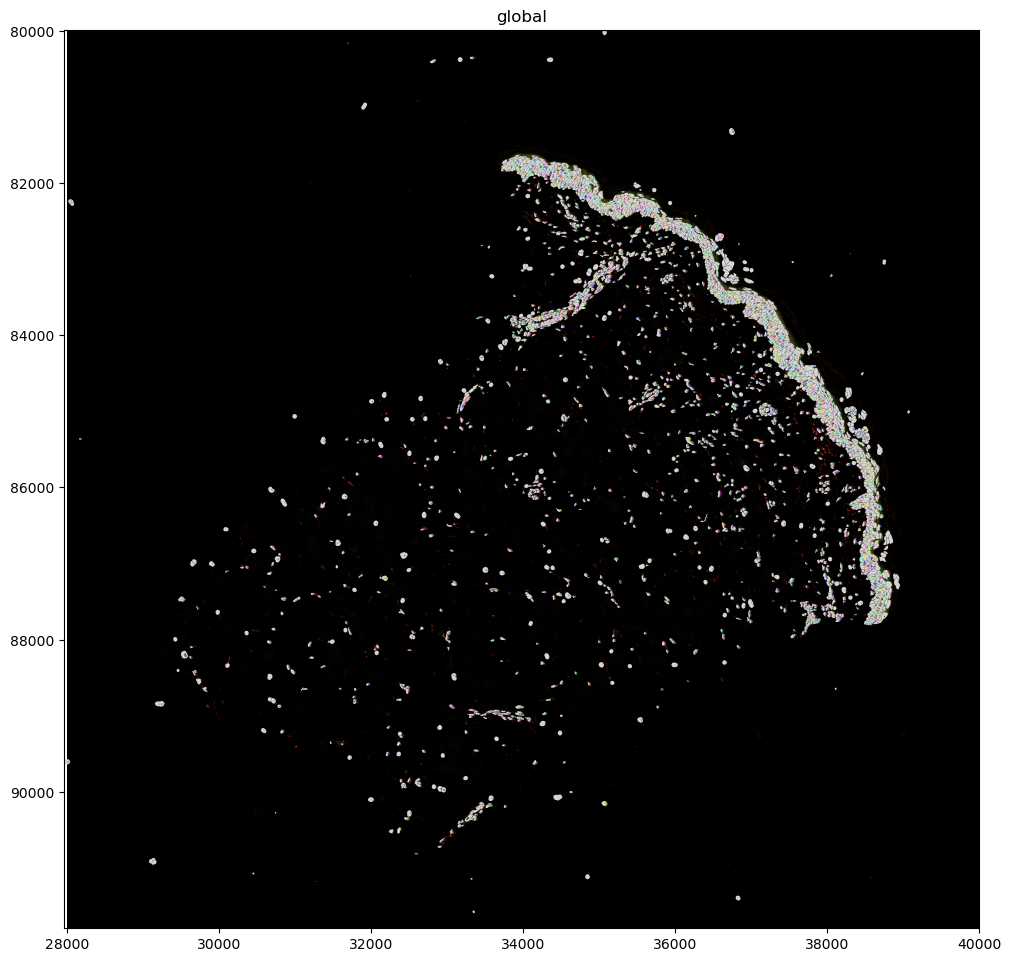

In [18]:
sdata.pl.render_images( #画指定的细胞形状
    "morphology_focus"
).pl.render_shapes(
    "cell_boundaries"
).pl.render_labels(
    "nucleus_labels"
).pl.show(
    coordinate_systems="global",
    figsize=(10, 10))

接着我们需要将spatialdata转换为rnalamp可用的格式，以便于我们后续的分析，rnalamp继承自spatialdata，换而言之，spatialdata的函数均可再rnalamp中调用

In [4]:
rdata = rnalamp(images=sdata.images,
                labels=sdata.labels,
                points=sdata.points,
                shapes=sdata.shapes,
                tables=sdata.tables)



导入由cal_clscore.py计算的基因对共定位结果

In [5]:
rdata.read_clscore(input_file='/mnt/dfc_data3/project/linyusen/database/17_RNA_colocation/02_spatial_AFL_colocation/KC.gene_colocation.all_NC_samples.csv') #读取计算好的结果


# 共定位分析

在此步骤中，我们将基于基因共定位分析得到的 clscore 及其显著性检验结果构建基因共定位网络，并采用 Leiden 社区检测算法对网络进行聚类，将具有显著共定位关系的基因划分为多个相对紧密的功能社区，为后续的社区质量评估与区域富集分析提供基础

In [6]:
rdata.build_gene_colocation_communities(pval_threshold=0.01,resolution=1.5,random_seed=42)  #设置参数划分社区


进行 Leiden 社区划分...
self.gene_colocation_community 划分得到 28 个社区


完成基因共定位网络的社区划分后，我们将对识别出的社区进行质量控制，主要从以下两个方面评估社区结构的合理性：
局部模块度贡献（Local Modularity Contribution）：通过置换检验，将真实社区的局部模块度贡献与随机打乱节点社区归属后得到的分布进行比较，评估真实社区的网络模块结构是否具有统计学上的显著性。 传导性（Conductance）：通过置换检验，将真实社区的传导性与随机社区的对应分布进行比较，评估社区内部连接与跨社区连接的相对关系。通常，传导性越低，说明社区内部连接相对于跨社区连接越紧密。
参数 n_permutations=500 表示每项检验执行 500 次随机置换。程序将输出各社区的统计结果，以及在代码设定的 p < 0.05 阈值下通过检验的社区数量。 社区质控结果可用于辅助判断当前社区划分是否合理。如果出现大量规模过小或结构不够紧密的社区，可结合质控结果考虑适当降低 resolution 参数；反之，则可考虑提高该参数，以探索更细粒度的社区结构。参数调整应综合考虑网络拓扑特征、社区规模分布及生物学背景，而不宜仅依据单一指标作出判断。

In [7]:
rdata.community_qc(n_permutations=500)  #质控聚类的社区，观察分辨率会不会太高，导致社区划分过于小，需要调整分辨率参数


正在进行置换检验（500次），请稍候...

=== 各社区局部模块度检验结果 ===
 Community  Size   Real_Q     Rand_Mean  Rand_Std    Z_score  P_value  Significant (p<0.05)
         6   243 0.012642 -1.403079e-05  0.000067 188.809167      0.0                  True
         4   300 0.013760 -2.394605e-05  0.000082 167.368084      0.0                  True
         1   375 0.015625 -2.493164e-05  0.000096 163.139356      0.0                  True
         5   298 0.009922 -1.995746e-05  0.000079 126.193403      0.0                  True
         0   798 0.021742 -4.992658e-05  0.000192 113.245641      0.0                  True
         8   174 0.005055 -1.455586e-05  0.000047 106.858526      0.0                  True
         2   373 0.009449 -2.148616e-05  0.000097  97.740784      0.0                  True
         9   138 0.003638 -1.390910e-05  0.000040  91.282471      0.0                  True
        11   115 0.002542 -1.028631e-05  0.000032  80.018335      0.0                  True
         3   315 0.005878 -2.697338e

最后，我们将利用基于 APEX-seq 数据整理的细胞器定位标记基因集，对聚类得到的各个基因共定位社区进行区域富集分析，以评估不同社区的整体细胞器定位倾向性，并探索基因共定位网络的空间功能特征。

In [8]:
rdata.community_enrich_region(gene_loc_file='/mnt/dfc_data3/project/linyusen/database/17_RNA_colocation/01_marker/data/gene_loc.csv') #计算社区富集的细胞区域


['Nucleus', 'Nucleolus', 'Lamina', 'Nuclear_Pore', 'Cytosol', 'ERM', 'OMM', 'ER_Lumen', 'PlasmaMembrane', 'Speckles', 'Lysosome']
Nucleus 富集的社区：
   community  comm_size  target_in_comm  target_fraction  expected_target  \
0          6        243              48         0.197531         8.381212   

   enrichment  odds_ratio       p_value    p_adjusted  enriched  
0    5.727096    9.609467  3.197895e-25  8.954107e-24      True  

Nucleolus 富集的社区：
   community  comm_size  target_in_comm  target_fraction  expected_target  \
0          6        243              25         0.102881         7.884956   

   enrichment  odds_ratio       p_value  p_adjusted  enriched  
0    3.170595    3.932126  1.598632e-07    0.000004      True  

Lamina 富集的社区：
   community  comm_size  target_in_comm  target_fraction  expected_target  \
0          6        243              30         0.123457         9.263445   
1          8        174              17         0.097701         6.633084   

   enrichment  odds_

# 保存结果


完成社区划分后，我们将按照社区逐个导出基因共定位网络，并以 Cytoscape 可读取的文本格式保存。
每个社区输出一个 community_<社区ID>.txt 文件，内容为制表符分隔的边表，包含以下字段：

source：边的起始基因
target：边的目标基因
p_val：共定位 p 值
effect_area：效应面积 这些文件可用于后续网络检查或导入 Cytoscape。

In [9]:
rdata.save_communities(output_dir='./community') #保存社区为cytoscape可导入的文件


共保存 28 个 community 网络


# 查看结果

读取某个社区的所有基因

In [14]:
community_index= 5 #读取第5个社区
print(rdata.gene_colocation_community[community_index][:10])  #显示社区5 其中10个基因名字

['A2ML1', 'DeprecatedCodeword_2162', 'ITPRID2', 'TNIP1', 'PLXNB2', 'TMEM123', 'FBP1', 'NDRG2', 'PDLIM4', 'PDCD6IP']


可视化指定社区的部分基因，前面分析，我们发现社区6富集大部分细胞核相关的marker基因，因此我们可视化社区6，观察这些基因是否呈现核内聚集

/mnt/dfc_data1/home/linyusen/miniconda/envs/lys4/lib/python3.12/functools.py:912: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


INFO     Your image has 4 channels. Sampling categorical colors and using multichannel strategy 'stack' to render. 
WARNING  No table name provided, using 'table' as fallback for color mapping.                                      
INFO     input has more than 103 categories. Uniform 'grey' color will be used for all categories.                 


/mnt/dfc_data1/home/linyusen/miniconda/envs/lys4/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  return fn(*args_all, **kw)
/mnt/dfc_data1/home/linyusen/miniconda/envs/lys4/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/mnt/dfc_data1/home/linyusen/miniconda/envs/lys4/lib/python3.12/site-packages/spatialdata_plot/pl/utils.py:1123: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)
/mnt/dfc_data1/home/linyusen/miniconda/envs/lys4/lib/python3.12/site-packages/spatialdata_plot/pl/render.py:928: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap

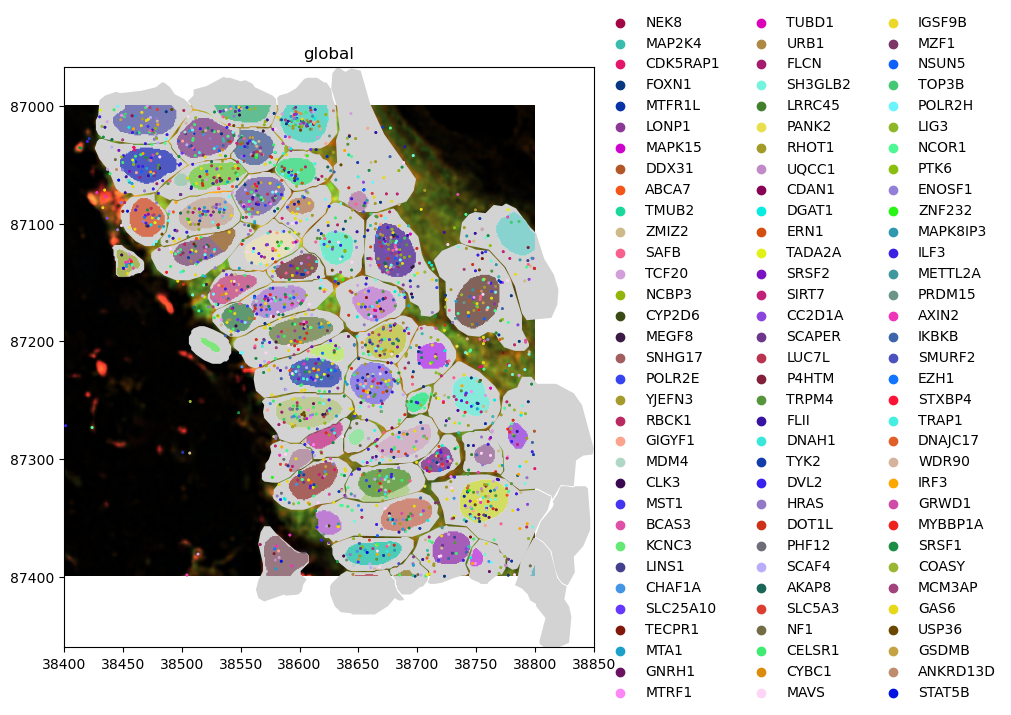

In [17]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import random
community_index = 6 #读取第6个社区
gene_list = rdata.gene_colocation_community[community_index]
gene_list = random.sample(gene_list,k=100)
random.seed(42)
# 为每个基因随机生成颜色
color_key = {
    gene: mcolors.to_hex(
        (random.random(), random.random(), random.random())
    )
    for gene in gene_list
}



bb_xmin = 38400
bb_ymin = 87000
bb_w = 400
bb_h = 400
bb_xmax = bb_xmin + bb_w
bb_ymax = bb_ymin + bb_h

#提取特定区域的sdata
from spatialdata import bounding_box_query
bounding_sdata = bounding_box_query(
        sdata,
        min_coordinate=[bb_xmin, bb_ymin],
        max_coordinate=[bb_xmax, bb_ymax],
        axes=("x", "y"),
        target_coordinate_system="global",
        filter_table=False,
    )


bounding_sdata.pl.render_images( #画指定的细胞形状
    "morphology_focus"
).pl.render_shapes(
    "cell_boundaries"
).pl.render_labels(
    "nucleus_labels"
).pl.render_points(
    element="transcripts",
    groups=gene_list,
    size=1,
    color="feature_name",
    palette=[color_key[g] for g in gene_list],
).pl.show(
    coordinate_systems="global",
    figsize=(10, 10))